# NE 630 — Lesson 22: Xenon Buildup and Reactivity Worth

In [1]:
import os
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import openmc
import openmc.data
import pandas as pd
from IPython.display import display
from scipy.integrate import solve_ivp

cross_sections = openmc.config.get("cross_sections") or os.getenv("OPENMC_CROSS_SECTIONS")
if not cross_sections or not Path(cross_sections).expanduser().is_file():
    raise RuntimeError("Set OPENMC_CROSS_SECTIONS to an installed cross_sections.xml.")
openmc.config["cross_sections"] = Path(cross_sections).expanduser().resolve()

BARN = 1.0e-24                    # cm^2 / barn
HOUR = 3600.0                     # s
PURPLE, ORANGE = "#512888", "#CA7C1B"
T_FUEL, T_COOLANT = 1200.0, 600.0  # K
GROUP_EDGES = [0.0, 1.0, 1.0e5, 2.0e7]  # eV; T, I, F as in Lesson 17
T, I, F = range(3)
FUEL, CLADDING, COOLANT = range(3)

## 1. Why is $^{135}$Xe such a strong poison?

Read the evaluated neutron data through OpenMC's `DataLibrary` and
`IncidentNeutron` interfaces. Reaction **MT = 102** is radiative capture,
$^{135}\mathrm{Xe}(n,\gamma){}^{136}\mathrm{Xe}$, the neutron-removal
channel retained in this lesson.

The point at **0.0253 eV** is a useful reference, not a spectrum average.
The temperature labels describe the target nuclei, not the neutron energy.
For subsequent calculations, use the available Xe table nearest the fuel
temperature; its actual temperature is reported.

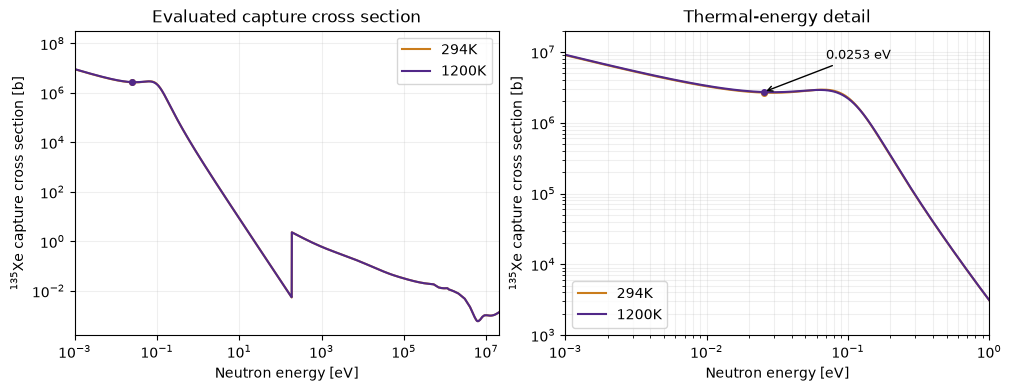

OpenMC 0.16.0; Xe table used below: 1200K
At 0.0253 eV: 2,664,214 b (294K)
At 0.0253 eV: 2,715,360 b (1200K)


In [2]:
library = openmc.data.DataLibrary.from_xml()
xe_entry = library.get_by_material("Xe135", data_type="neutron")
if xe_entry is None:
    raise RuntimeError("The configured neutron library does not contain Xe135.")
xe_data = openmc.data.IncidentNeutron.from_hdf5(xe_entry["path"])

def nearest_temperature(target):
    return min(xe_data.temperatures, key=lambda label: abs(float(label[:-1]) - target))

room_label = nearest_temperature(294.0)
fuel_label = nearest_temperature(T_FUEL)
sigma_xe_E = xe_data[102].xs[fuel_label]  # callable; energy in eV, result in barns
E_ref = 0.0253

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), layout="constrained")
for label, color in zip((room_label, fuel_label), (ORANGE, PURPLE)):
    xs = xe_data[102].xs[label]
    positive = xs.y > 0.0
    for ax in axes:
        ax.loglog(xs.x[positive], xs.y[positive], color=color, label=label)
        ax.plot(E_ref, xs(E_ref), "o", color=color, ms=4)
for ax in axes:
    ax.set_xlabel("Neutron energy [eV]")
    ax.set_ylabel(r"$^{135}$Xe capture cross section [b]")
    ax.grid(which="both", alpha=0.2)
    ax.legend()
axes[0].set(xlim=(1.0e-3, 2.0e7), title="Evaluated capture cross section")
axes[1].set(xlim=(1.0e-3, 1.0), ylim=(1.0e3, 2.0e7), title="Thermal-energy detail")
axes[1].annotate("0.0253 eV", xy=(E_ref, sigma_xe_E(E_ref)),
                 xytext=(0.07, 8.0e6), arrowprops={"arrowstyle": "->"}, fontsize=9)
plt.show()

print(f"OpenMC {openmc.__version__}; Xe table used below: {fuel_label}")
print(f"At {E_ref} eV: {xe_data[102].xs[room_label](E_ref):,.0f} b ({room_label})")
print(f"At {E_ref} eV: {sigma_xe_E(E_ref):,.0f} b ({fuel_label})")

## 2. A short numerical solution of the iodine–xenon system

Use the Lesson 22 yields and half-lives:
$\gamma_I=0.0639$, $\gamma_{Xe}=0.00237$,
$t_{1/2,I}=6.7$ h, and $t_{1/2,Xe}=9.2$ h.
The effective iodine yield includes the short-lived precursors feeding
iodine; the Xe yield is direct production, so iodine's contribution is
not counted twice. Neglect iodine absorption, fuel depletion, other poisons,
and changes in spectrum or temperature.

For number densities **per cm$^3$ of fuel**, the balances are

$$
\frac{dN_I}{dt}=\gamma_I\bar{\Sigma}_f\phi(t)-\lambda_I N_I,
$$
$$
\frac{dN_{Xe}}{dt}=\gamma_{Xe}\bar{\Sigma}_f\phi(t)+\lambda_I N_I
-\left[\lambda_{Xe}+\bar{\sigma}_a^{Xe}\phi(t)\right]N_{Xe}.
$$

Here $\phi$ is the **all-energy, volume-average fuel flux**,
$\bar{\Sigma}_f$ is the matching all-energy fission cross section, and
$\bar{\sigma}_a^{Xe}$ is the all-energy Xe capture average from Section 2.


**Experiment:** start without iodine or xenon, operate for 72 hours,
then shut down ($\phi=0$) and follow the inventories to 120 hours.
The prescribed flux represents an externally controlled operating history,
not a coupled reactor-kinetics calculation.

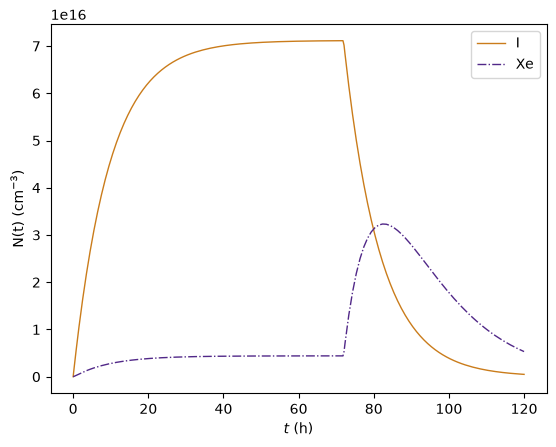

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

def dNdt(t, N, phi, sig_a_Xe, Sigma_f):
  gamma_I, gamma_Xe = 0.0639, 0.00237
  lambda_I, lambda_Xe = 0.693/(6.7*3600), 0.693/(9.2*3600)
  sig_a_Xe = sig_a_Xe*1e-24
  N_I, N_Xe = N
  dN_Idt = -lambda_I*N_I + gamma_I*Sigma_f*phi(t)
  dN_Xdt = -lambda_Xe*N_Xe + lambda_I*N_I + \
            (gamma_Xe*Sigma_f-sig_a_Xe*N_Xe)*phi(t)
  return dN_Idt, dN_Xdt

hour=3600; day = 24*hour;

flux = lambda t: 2e14 if t < 3*day else 0.0

result = solve_ivp(fun=dNdt, t_span=(0.0, 5*day), 
  y0=(0, 0), args=(flux, 2.3e6, 0.16), max_step=1*hour)
t = result.t/3600; N_I, N_Xe = result.y

orange, purple = "#CA7C1B", "#512888"
plt.plot(t, N_I, color=orange, lw=1, label="I")
plt.plot(t, N_Xe, color=purple, lw=1, ls="-.", label="Xe")
plt.xlabel("$t$ (h)"); plt.ylabel("N(t) (cm$^{-3}$)")
plt.legend()
plt.show()